<a href="https://colab.research.google.com/github/njonjoann12-sys/Class_Project_2/blob/main/Week_6_Assignment_%7C_Olkaria_Geothermal_Pipeline_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This project applies unsupervised machine learning to experimental pipeline thermal-response data. The aim is to identify groups of observations with similar thermal characteristics using the K-means clustering algorithm.

**Features selected for investigation:**
1.   Inlet temperature (°C)- describes the temperature of fluid entering the pipeline.
2.   Outlet temperature (°C)- describes the temperature of fluid leaving the pipeline.
3. Measured heat transfer (W)- indicates the measured thermal transfer in the experiment.

These features were selected because they describe the thermal conditions of the pipeline and may help identify groups of observations with similar heat-transfer behaviour. The K-means algorithm will be used to group observations based on similarities among these variables.


In [2]:
from google.colab import files
import pandas as pd

# Upload the experimental pipeline dataset
uploaded = files.upload()

# Get the uploaded Excel filename
file_path = next(iter(uploaded.keys()))

# Display available worksheets
excel_file = pd.ExcelFile(file_path)

print("Available worksheets:")
print(excel_file.sheet_names)

Saving Experimental_and_modelling_Data-Ex_Setup.xlsx to Experimental_and_modelling_Data-Ex_Setup (1).xlsx
Available worksheets:
['PipelineStepChange', 'GroundStepChange', 'Weighting Factors series', 'GroundHeatTrasnfer']


In [3]:
# Inspect the pipeline temperature data
pipeline_data = pd.read_excel(
    file_path,
    sheet_name="PipelineStepChange"
)

print("PIPELINE STEP CHANGE DATA")
print("Shape:", pipeline_data.shape)
print("Column names:")
print(pipeline_data.columns.tolist())
display(pipeline_data.head())

# Inspect the ground heat-transfer data
heat_data = pd.read_excel(
    file_path,
    sheet_name="GroundHeatTrasnfer"
)

print("\nGROUND HEAT-TRANSFER DATA")
print("Shape:", heat_data.shape)
print("Column names:")
print(heat_data.columns.tolist())
display(heat_data.head())

PIPELINE STEP CHANGE DATA
Shape: (759, 9)
Column names:
['Measured and predicted outlet temperatures by the numerical models for the experiment of the step change to the buried pipe ', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']


,Measured and predicted outlet temperatures by the numerical models for the experiment of the step change to the buried pipe,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Time (h),Inlet Temperature- Measured (Cº),Outlet Temperature- Measured (Cº),3D model- OpenFOAM (Cº),DTN model (Cº),Combined DTN-PFST model (Cº),Error (3D model),Error (DTN model),Error (Combined DTN-PFST model)
2,0,38.15833,16.35428,17.8176,16.8176,16.99984,-1.46332,-0.46332,-0.64556
3,0.05556,38.23205,35.32343,35.5646,35.65434,33.54345,-0.24117,-0.33091,1.77998
4,0.11111,38.52088,35.55219,35.6427,35.21056,33.38371,-0.09051,0.34163,2.16848



GROUND HEAT-TRANSFER DATA
Shape: (759, 5)
Column names:
['Measured and calculated ground surface heat transfer for the case of the step change to the buried pipe.', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,Measured and calculated ground surface heat transfer for the case of the step change to the buried pipe.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,Time (h),Measured heat transfer (W),3D model-OpenFOAM (W),DTN model (W),Combined DTN-PFST (W)
2,0,0,0,0,0
3,0.05556,3.98535,6.19048,3.98535,2.04377
4,0.11111,5.78131,5.78964,3.35239,4.31478


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [4]:
# Display the first six rows of each worksheet
for sheet in ["PipelineStepChange", "GroundHeatTrasnfer"]:
    print("\n" + "=" * 60)
    print("WORKSHEET:", sheet)

    preview = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None,
        nrows=6
    )

    display(preview)


WORKSHEET: PipelineStepChange


,0,1,2,3,4,5,6,7,8
0,Measured and predicted outlet temperatures by ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Time (h),Inlet Temperature- Measured (Cº),Outlet Temperature- Measured (Cº),3D model- OpenFOAM (Cº),DTN model (Cº),Combined DTN-PFST model (Cº),Error (3D model),Error (DTN model),Error (Combined DTN-PFST model)
3,0,38.15833,16.35428,17.8176,16.8176,16.99984,-1.46332,-0.46332,-0.64556
4,0.05556,38.23205,35.32343,35.5646,35.65434,33.54345,-0.24117,-0.33091,1.77998
5,0.11111,38.52088,35.55219,35.6427,35.21056,33.38371,-0.09051,0.34163,2.16848



WORKSHEET: GroundHeatTrasnfer


,0,1,2,3,4
0,Measured and calculated ground surface heat tr...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,Time (h),Measured heat transfer (W),3D model-OpenFOAM (W),DTN model (W),Combined DTN-PFST (W)
3,0,0,0,0,0
4,0.05556,3.98535,6.19048,3.98535,2.04377
5,0.11111,5.78131,5.78964,3.35239,4.31478


In [5]:
# Load both worksheets using row 2 as the header
pipeline_data = pd.read_excel(
    file_path,
    sheet_name="PipelineStepChange",
    header=2
)

heat_data = pd.read_excel(
    file_path,
    sheet_name="GroundHeatTrasnfer",
    header=2
)

# Display the correctly loaded columns
print("Pipeline temperature columns:")
print(pipeline_data.columns.tolist())

print("\nGround heat-transfer columns:")
print(heat_data.columns.tolist())

# Display the first five observations
display(pipeline_data.head())
display(heat_data.head())

Pipeline temperature columns:
['Time (h)', 'Inlet Temperature- Measured (Cº)', 'Outlet Temperature- Measured (Cº)', '3D model- OpenFOAM (Cº)', 'DTN model (Cº)', 'Combined DTN-PFST model (Cº)', 'Error (3D model)', 'Error (DTN model)', 'Error (Combined DTN-PFST model)']

Ground heat-transfer columns:
['Time (h)', 'Measured heat transfer (W)', '3D model-OpenFOAM (W)', 'DTN model (W)', 'Combined DTN-PFST (W)']


,Time (h),Inlet Temperature- Measured (Cº),Outlet Temperature- Measured (Cº),3D model- OpenFOAM (Cº),DTN model (Cº),Combined DTN-PFST model (Cº),Error (3D model),Error (DTN model),Error (Combined DTN-PFST model)
0,0.00000,38.15833,16.35428,17.8176,16.81760,16.99984,-1.46332,-0.46332,-0.64556
1,0.05556,38.23205,35.32343,35.5646,35.65434,33.54345,-0.24117,-0.33091,1.77998
2,0.11111,38.52088,35.55219,35.6427,35.21056,33.38371,-0.09051,0.34163,2.16848
3,0.16667,38.18224,36.57940,35.9462,35.88715,35.57472,0.63320,0.69225,1.00468
4,0.22222,38.23650,36.32526,36.1229,36.14857,35.97448,0.20236,0.17669,0.35078


,Time (h),Measured heat transfer (W),3D model-OpenFOAM (W),DTN model (W),Combined DTN-PFST (W)
0,0.00000,0.00000,0.00000,0.00000,0.00000
1,0.05556,3.98535,6.19048,3.98535,2.04377
2,0.11111,5.78131,5.78964,3.35239,4.31478
3,0.16667,5.78131,6.12731,3.15425,6.93352
4,0.22222,10.09823,7.37870,2.71837,9.90806


In [6]:
import numpy as np

# Check whether both worksheets have the same number of rows
print("Pipeline worksheet rows:", len(pipeline_data))
print("Heat-transfer worksheet rows:", len(heat_data))

# Check whether the time values match
same_time = np.allclose(
    pipeline_data["Time (h)"].to_numpy(),
    heat_data["Time (h)"].to_numpy(),
    equal_nan=True
)

print("Do the time values match?", same_time)

Pipeline worksheet rows: 757
Heat-transfer worksheet rows: 757
Do the time values match? True


In [7]:
# Create a dataset using the three selected features
df = pd.DataFrame({
    "Time (h)": pipeline_data["Time (h)"],
    "Inlet Temperature (C)": pipeline_data[
        "Inlet Temperature- Measured (Cº)"
    ],
    "Outlet Temperature (C)": pipeline_data[
        "Outlet Temperature- Measured (Cº)"
    ],
    "Measured Heat Transfer (W)": heat_data[
        "Measured heat transfer (W)"
    ]
})

# Display the first five rows
display(df.head())

# Check the dataset dimensions and missing values
print("Dataset dimensions:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

,Time (h),Inlet Temperature (C),Outlet Temperature (C),Measured Heat Transfer (W)
0,0.00000,38.15833,16.35428,0.00000
1,0.05556,38.23205,35.32343,3.98535
2,0.11111,38.52088,35.55219,5.78131
3,0.16667,38.18224,36.57940,5.78131
4,0.22222,38.23650,36.32526,10.09823


Dataset dimensions: (757, 4)

Missing values:
Time (h)                      0
Inlet Temperature (C)         0
Outlet Temperature (C)        0
Measured Heat Transfer (W)    0
dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

# Select the three features for clustering
features = [
    "Inlet Temperature (C)",
    "Outlet Temperature (C)",
    "Measured Heat Transfer (W)"
]

X = df[features]

# Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display the standardised data
scaled_df = pd.DataFrame(X_scaled, columns=features)
display(scaled_df.head())

print("Scaled dataset dimensions:", X_scaled.shape)

,Inlet Temperature (C),Outlet Temperature (C),Measured Heat Transfer (W)
0,3.434152,-27.058600,-5.834648
1,5.093780,-2.313006,-5.601873
2,11.596089,-2.014585,-5.496975
3,3.972428,-0.674571,-5.496975
4,5.193961,-1.006101,-5.244834


Scaled dataset dimensions: (757, 3)


In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Display the results
results = pd.DataFrame({
    "Number of clusters (k)": list(k_values),
    "Inertia": inertias,
    "Silhouette score": silhouette_scores
})

display(results)

,Number of clusters (k),Inertia,Silhouette score
0,2,1491.966542,0.951197
1,3,825.741332,0.766875
2,4,606.708150,0.642247
3,5,460.759933,0.420818
4,6,377.449420,0.441719
5,7,309.560131,0.443505
6,8,266.448936,0.450524
7,9,230.165163,0.352898
8,10,202.343017,0.347954


In [10]:
# Apply the final K-means model
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the number of observations in each cluster
print("Cluster counts:")
print(df["Cluster"].value_counts().sort_index())

# Display the first five rows
display(df.head())

Cluster counts:
Cluster
0    756
1      1
Name: count, dtype: int64


,Time (h),Inlet Temperature (C),Outlet Temperature (C),Measured Heat Transfer (W),Cluster
0,0.00000,38.15833,16.35428,0.00000,1
1,0.05556,38.23205,35.32343,3.98535,0
2,0.11111,38.52088,35.55219,5.78131,0
3,0.16667,38.18224,36.57940,5.78131,0
4,0.22222,38.23650,36.32526,10.09823,0


In [11]:
# Summarise the characteristics of each cluster
cluster_summary = df.groupby("Cluster")[
    [
        "Inlet Temperature (C)",
        "Outlet Temperature (C)",
        "Measured Heat Transfer (W)"
    ]
].agg(["count", "mean", "min", "max"])

display(cluster_summary)

Inlet Temperature (C)                                 \
                        count       mean       min       max   
Cluster                                                        
0                         756  38.005585  37.81580  38.52088   
1                           1  38.158330  38.15833  38.15833   

        Outlet Temperature (C)                                 \
                         count       mean       min       max   
Cluster                                                         
0                          756  37.123941  35.32343  37.28126   
1                            1  16.354280  16.35428  16.35428   

        Measured Heat Transfer (W)                                  
                             count        mean      min        max  
Cluster                                                             
0                              756  100.027494  3.98535  114.23353  
1                                1    0.000000  0.00000    0.00000

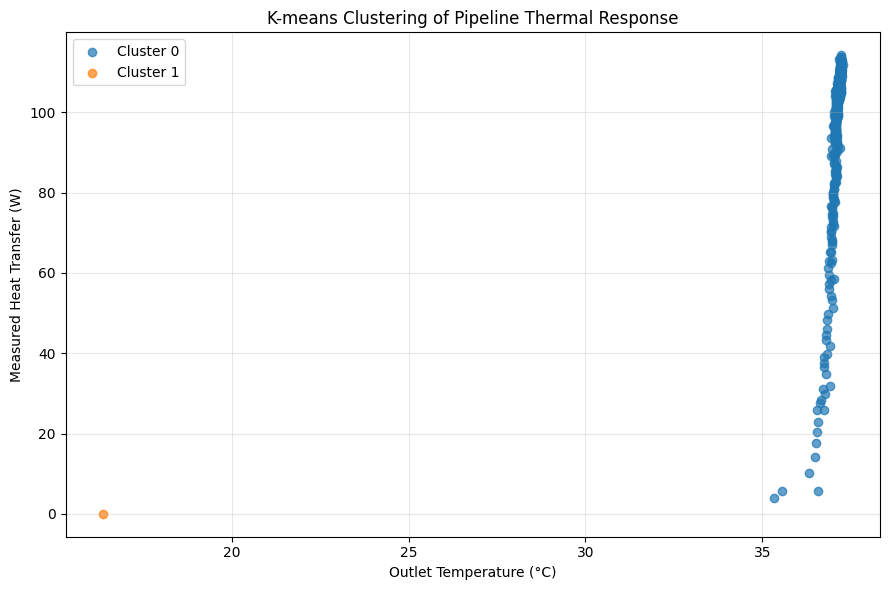

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    subset = df[df["Cluster"] == cluster]
    plt.scatter(
        subset["Outlet Temperature (C)"],
        subset["Measured Heat Transfer (W)"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Outlet Temperature (°C)")
plt.ylabel("Measured Heat Transfer (W)")
plt.title("K-means Clustering of Pipeline Thermal Response")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
df_later = df[df["Time (h)"] > 0].copy()

# Select and standardise the three clustering features again
X_later = df_later[features]
X_later_scaled = StandardScaler().fit_transform(X_later)

# Compare cluster counts from 2 to 6
comparison = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_later_scaled)

    comparison.append({
        "Number of clusters": k,
        "Silhouette score": silhouette_score(
            X_later_scaled, labels
        ),
        "Smallest cluster size": pd.Series(labels).value_counts().min()
    })

display(pd.DataFrame(comparison))

,Number of clusters,Silhouette score,Smallest cluster size
0,2,0.774588,38
1,3,0.740862,2
2,4,0.532785,2
3,5,0.369847,2
4,6,0.357652,2


In [14]:
# Fit the selected K-means model with two clusters
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df_later["Cluster"] = final_kmeans.fit_predict(X_later_scaled)

# Display the number of observations in each cluster
print("Observations per cluster:")
print(df_later["Cluster"].value_counts().sort_index())

# Summarise the thermal characteristics of each cluster
cluster_summary = df_later.groupby("Cluster")[
    features
].agg(["count", "mean", "min", "max"]).round(3)

display(cluster_summary)


Observations per cluster:
Cluster
0    718
1     38
Name: count, dtype: int64


Inlet Temperature (C)                         Outlet Temperature (C)  \
                        count    mean     min     max                  count   
Cluster                                                                        
0                         718  38.001  37.816  38.177                    718   
1                          38  38.089  37.887  38.521                     38   

                                Measured Heat Transfer (W)                   \
           mean     min     max                      count     mean     min   
Cluster                                                                       
0        37.146  36.896  37.281                        718  103.260  57.308   
1        36.711  35.323  37.016                         38   38.959   3.985   

                  
             max  
Cluster           
0        114.234  
1         68.991

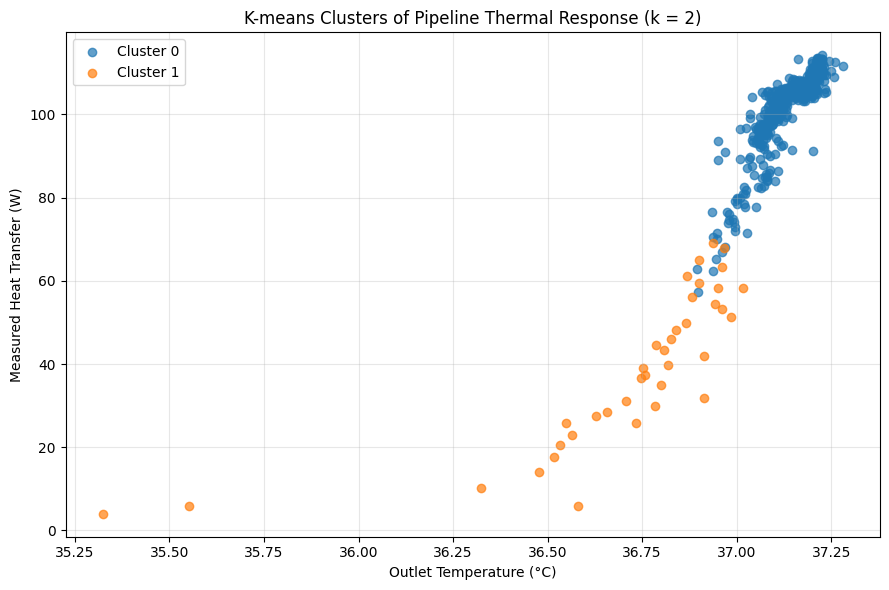

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(df_later["Cluster"].unique()):
    subset = df_later[df_later["Cluster"] == cluster]

    plt.scatter(
        subset["Outlet Temperature (C)"],
        subset["Measured Heat Transfer (W)"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Outlet Temperature (°C)")
plt.ylabel("Measured Heat Transfer (W)")
plt.title("K-means Clusters of Pipeline Thermal Response (k = 2)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Results and Discussion**

The K-means clustering algorithm was applied to the experimental pipeline thermal-response dataset using inlet temperature, outlet temperature, and measured heat transfer as the clustering features. Before clustering, the features were standardised to ensure that differences in their numerical scales did not disproportionately influence the model.

The initial analysis evaluated cluster numbers from two to ten. The highest silhouette score was obtained at (k=2), with a score of 0.951. However, this solution separated the initial observation at time zero from the remaining 756 observations, producing a highly unbalanced clustering result. The initial observation had an outlet temperature of 16.354 °C and measured heat transfer of 0 W.

To investigate the remaining thermal-response patterns, the initial observation was temporarily excluded and the clustering analysis repeated. The two-cluster solution produced a silhouette score of 0.775, higher than the scores obtained for three to six clusters. The final model identified two groups comprising 718 and 38 observations, respectively.

Cluster 0 contained 718 observations, with mean outlet temperature of 37.146 °C and mean measured heat transfer of 103.260 W. Cluster 1 contained 38 observations, with mean outlet temperature of 36.711 °C and mean measured heat transfer of 38.959 W. These results indicate that the clusters differ mainly in their measured heat-transfer characteristics, while their mean inlet temperatures are similar.

The scatter plot illustrates this pattern, with Cluster 0 generally associated with higher heat-transfer measurements and Cluster 1 containing many lower heat-transfer observations. Some overlap between the groups is visible, indicating that the clusters are not completely distinct when viewed using outlet temperature and heat transfer alone.

The identified groups may represent different stages or conditions of the experimental pipeline's thermal response. However, clustering identifies statistical similarities rather than physical causes. Additional analysis would be required to establish whether these groups correspond to particular heat-transfer mechanisms or operating conditions. The experimental dataset is not direct field data from the Olkaria geothermal field; therefore, the findings provide a potential analytical approach for future geothermal pipeline studies rather than direct evidence of Olkaria pipeline performance.

**Conclusion**

The analysis illustrates the application of unsupervised machine learning to identify patterns in experimental pipeline thermal-response data. After standardisation and comparison of different cluster numbers, a two-cluster K-means model was selected for the analysis excluding the initial transient observation. The resulting groups differed mainly in measured heat transfer and, to a lesser extent, outlet temperature. These findings show how clustering can help organise thermal-response observations into groups for further investigation. Future work could apply the methodology to field measurements from the Olkaria geothermal field to investigate whether similar thermal-response patterns occur under actual operating conditions.